In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from ucimlrepo import fetch_ucirepo

# Set plot style
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (12, 6)

# ==========================================
# 1. LOAD DATASET (Direct from UCI Repo)
# ==========================================
print("Fetching AI4I 2020 Predictive Maintenance Dataset...")
ai4i_2020 = fetch_ucirepo(id=601)

X = ai4i_2020.data.features
y = ai4i_2020.data.targets
df = pd.concat([X, y], axis=1)

print(f"\nDataset Shape: {df.shape}")
print("\nFirst 5 Rows:")
print(df.head())


Fetching AI4I 2020 Predictive Maintenance Dataset...

Dataset Shape: (10000, 12)

First 5 Rows:
  Type  Air temperature  Process temperature  Rotational speed  Torque  \
0    M            298.1                308.6              1551    42.8   
1    L            298.2                308.7              1408    46.3   
2    L            298.1                308.5              1498    49.4   
3    L            298.2                308.6              1433    39.5   
4    L            298.2                308.7              1408    40.0   

   Tool wear  Machine failure  TWF  HDF  PWF  OSF  RNF  
0          0                0    0    0    0    0    0  
1          3                0    0    0    0    0    0  
2          5                0    0    0    0    0    0  
3          7                0    0    0    0    0    0  
4          9                0    0    0    0    0    0  


In [2]:

# ==========================================
# 2. DATA INTEGRITY & MISSING VALUES
# ==========================================
print("\n--- Data Types & Missing Values ---")
info_df = pd.DataFrame({
    "Dtype": df.dtypes,
    "Missing_Count": df.isnull().sum(),
    "Missing_Pct": (df.isnull().sum() / len(df)) * 100,
    "Unique_Values": df.nunique()
})
print(info_df)

print(f"\nDuplicate Rows: {df.duplicated().sum()}")



--- Data Types & Missing Values ---
                       Dtype  Missing_Count  Missing_Pct  Unique_Values
Type                  object              0          0.0              3
Air temperature      float64              0          0.0             93
Process temperature  float64              0          0.0             82
Rotational speed       int64              0          0.0            941
Torque               float64              0          0.0            577
Tool wear              int64              0          0.0            246
Machine failure        int64              0          0.0              2
TWF                    int64              0          0.0              2
HDF                    int64              0          0.0              2
PWF                    int64              0          0.0              2
OSF                    int64              0          0.0              2
RNF                    int64              0          0.0              2

Duplicate Rows: 0


In [3]:

# ==========================================
# 3. CONSTRUCT MULTI-CLASS TARGET
# ==========================================
# The dataset provides a binary 'Machine failure' flag and 5 binary failure modes:
# TWF (Tool Wear Failure), HDF (Heat Dissipation Failure), PWF (Power Failure),
# OSF (Overstrain Failure), RNF (Random Failures).

failure_cols = ["TWF", "HDF", "PWF", "OSF", "RNF"]

# Check how many rows have simultaneous multiple failure modes
df["Failure_Mode_Sum"] = df[failure_cols].sum(axis=1)
print("\n--- Simultaneous Failure Modes Count ---")
print(df["Failure_Mode_Sum"].value_counts())

# Edge case check: Machine failure == 1, but all 5 specific failure flags == 0
anomalies = df[(df["Machine failure"] == 1) & (df["Failure_Mode_Sum"] == 0)]
print(f"\nRows where Machine failure=1 but all specific modes=0: {len(anomalies)}")

# Edge case check: RNF=1 while Machine failure=0 (documented quirk in AI4I dataset)
rnf_quirk = df[(df["Machine failure"] == 0) & (df["RNF"] == 1)]
print(f"Rows where Machine failure=0 but RNF=1: {len(rnf_quirk)}")

def assign_multiclass_target(row):
    if row["Machine failure"] == 0:
        return "No Failure"
    active_modes = [col for col in failure_cols if row[col] == 1]
    if len(active_modes) == 0:
        return "Unexplained Failure"
    elif len(active_modes) == 1:
        return active_modes[0]
    else:
        return "Multiple Failures" # Or prioritize primary failure mode

df["Target_Class"] = df.apply(assign_multiclass_target, axis=1)

print("\n--- Multi-Class Target Distribution ---")
class_dist = df["Target_Class"].value_counts()
class_pct = df["Target_Class"].value_counts(normalize=True) * 100
print(pd.DataFrame({"Count": class_dist, "Percentage (%)": class_pct.round(3)}))



--- Simultaneous Failure Modes Count ---
Failure_Mode_Sum
0    9652
1     324
2      23
3       1
Name: count, dtype: int64

Rows where Machine failure=1 but all specific modes=0: 9
Rows where Machine failure=0 but RNF=1: 18

--- Multi-Class Target Distribution ---
                     Count  Percentage (%)
Target_Class                              
No Failure            9661           96.61
HDF                    106            1.06
PWF                     80            0.80
OSF                     78            0.78
TWF                     42            0.42
Multiple Failures       24            0.24
Unexplained Failure      9            0.09


In [4]:

# ==========================================
# 4. SUMMARY STATISTICS & OUTLIERS
# ==========================================
num_cols = [
    "Air temperature",
    "Process temperature",
    "Rotational speed",
    "Torque",
    "Tool wear"
]

print("\n--- Numerical Summary Statistics ---")
print(df[num_cols].describe().T[["min", "25%", "50%", "75%", "max", "mean", "std"]])




--- Numerical Summary Statistics ---
                        min     25%     50%     75%     max        mean  \
Air temperature       295.3   298.3   300.1   301.5   304.5   300.00493   
Process temperature   305.7   308.8   310.1   311.1   313.8   310.00556   
Rotational speed     1168.0  1423.0  1503.0  1612.0  2886.0  1538.77610   
Torque                  3.8    33.2    40.1    46.8    76.6    39.98691   
Tool wear               0.0    53.0   108.0   162.0   253.0   107.95100   

                            std  
Air temperature        2.000259  
Process temperature    1.483734  
Rotational speed     179.284096  
Torque                 9.968934  
Tool wear             63.654147  


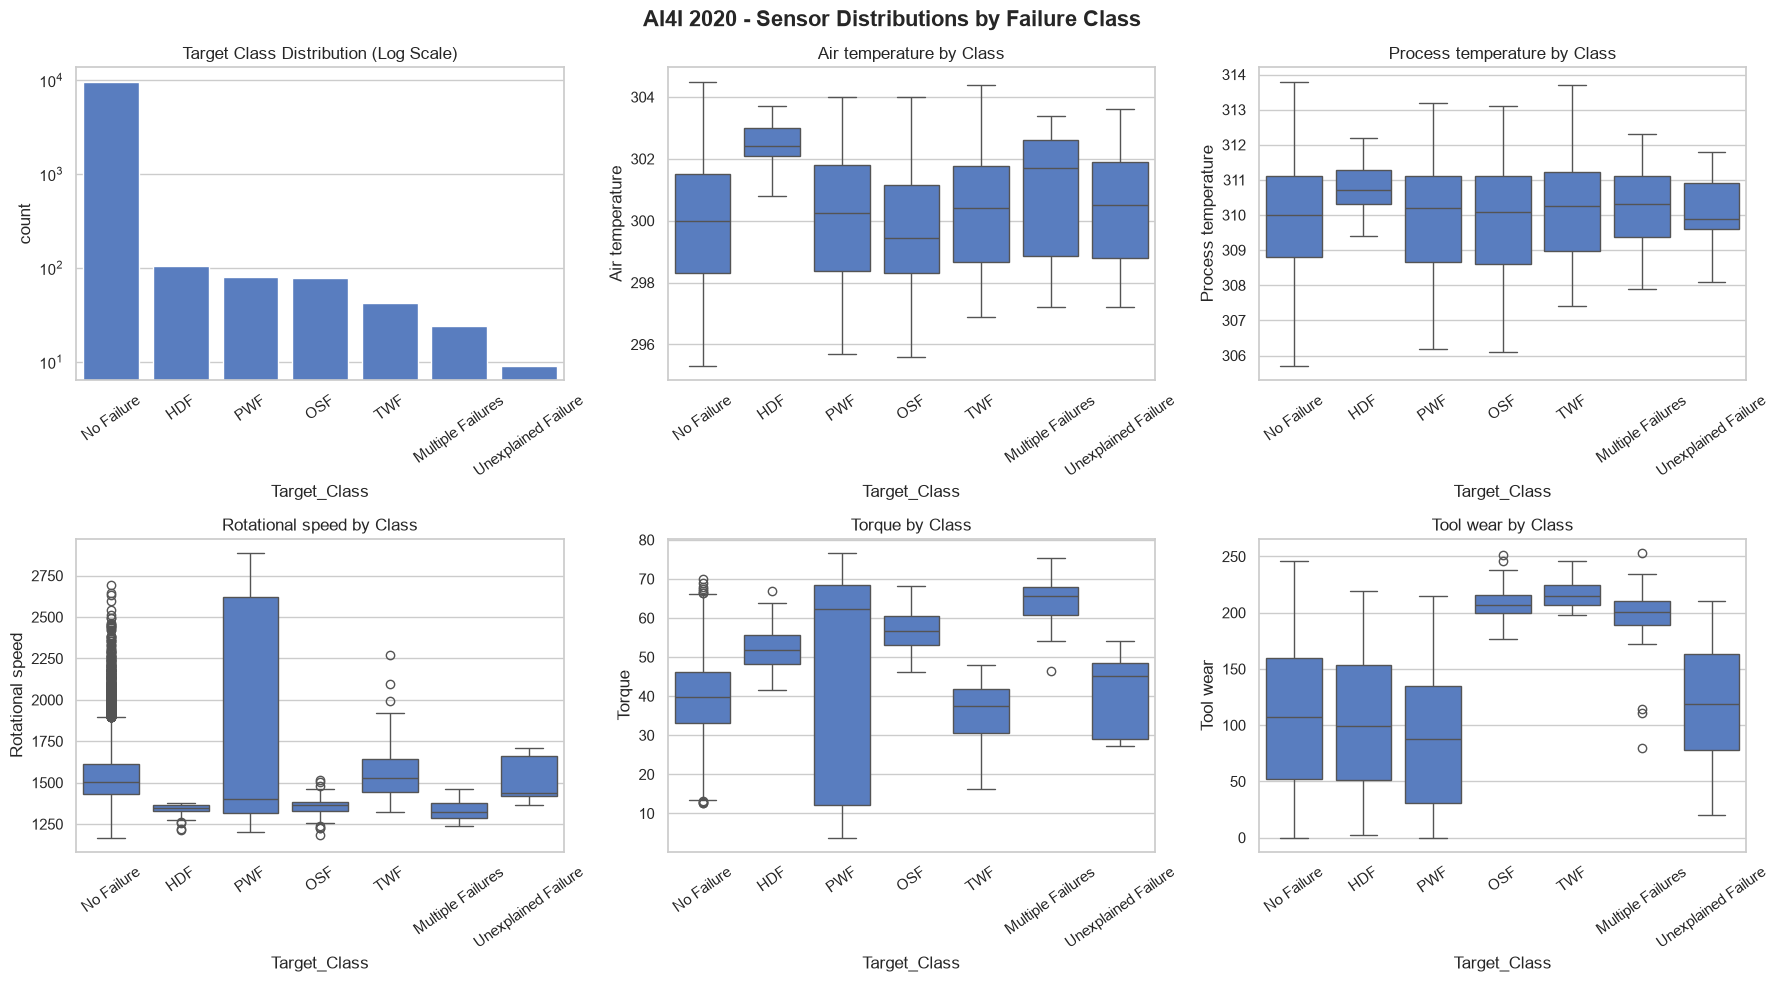

In [5]:
# ==========================================
# 5. VISUALIZATIONS
# ==========================================
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle("AI4I 2020 - Sensor Distributions by Failure Class", fontsize=16, fontweight="bold")

# Plot 1: Class Imbalance (Log Scale)
sns.countplot(
    data=df,
    x="Target_Class",
    order=df["Target_Class"].value_counts().index,
    ax=axes[0, 0]
)
axes[0, 0].set_yscale("log")
axes[0, 0].set_title("Target Class Distribution (Log Scale)")
axes[0, 0].tick_params(axis="x", rotation=35)

# Plots 2-6: Boxplots of Numerical Sensors across Target Classes
for idx, col in enumerate(num_cols):
    row_idx = (idx + 1) // 3
    col_idx = (idx + 1) % 3
    sns.boxplot(
        data=df,
        x="Target_Class",
        y=col,
        order=df["Target_Class"].value_counts().index,
        ax=axes[row_idx, col_idx]
    )
    axes[row_idx, col_idx].set_title(f"{col} by Class")
    axes[row_idx, col_idx].tick_params(axis="x", rotation=35)

plt.tight_layout()
plt.show()



--- Failure Rate by Product Quality Type ---
Target_Class   HDF  Multiple Failures  No Failure   OSF   PWF  TWF  \
Type                                                                 
H             0.80               0.10       97.91  0.10  0.40  0.6   
L             1.13               0.28       96.08  1.22  0.82  0.4   
M             1.00               0.20       97.23  0.13  0.90  0.4   

Target_Class  Unexplained Failure  
Type                               
H                            0.10  
L                            0.07  
M                            0.13  


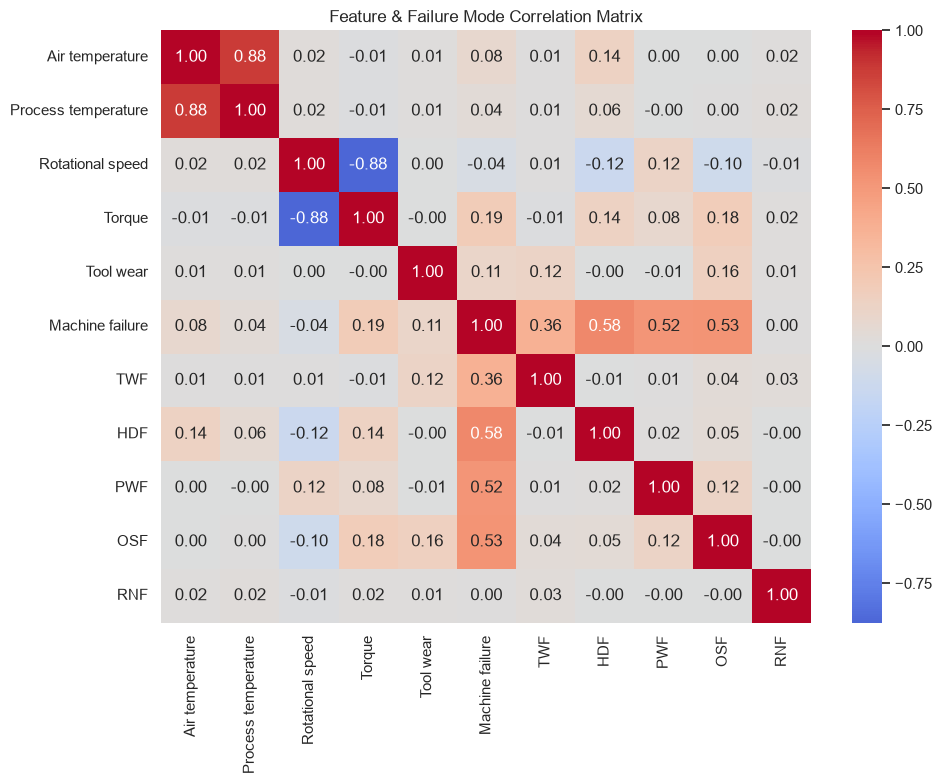

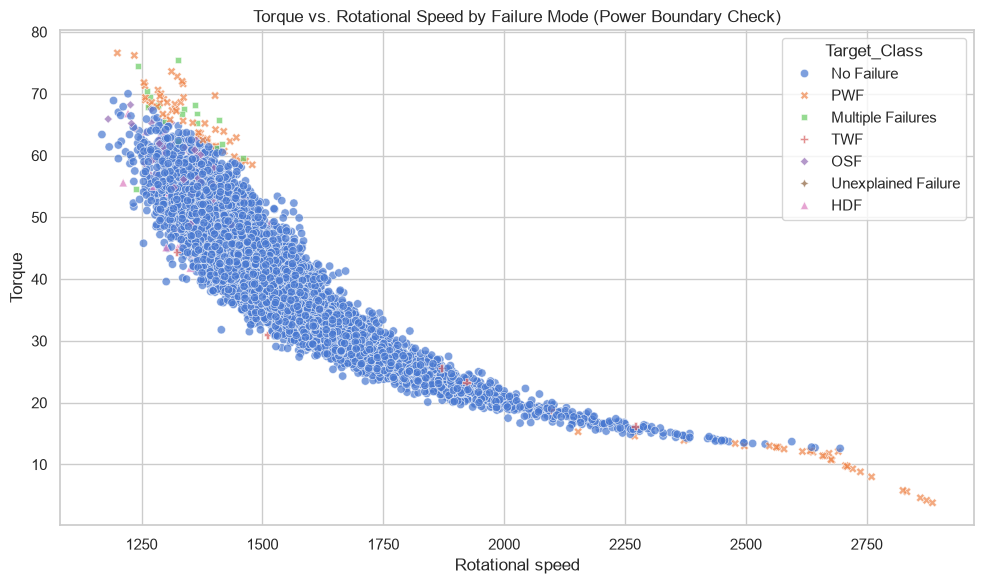

In [6]:

# ==========================================
# 6. PRODUCT TYPE & DOMAIN PHYSICS CHECKS
# ==========================================
# Machine Quality Type: L (Low - 50%), M (Medium - 30%), H (High - 20%)
print("\n--- Failure Rate by Product Quality Type ---")
type_ct = pd.crosstab(df["Type"], df["Target_Class"], normalize="index") * 100
print(type_ct.round(2))

# Correlation Heatmap of Numerical Features + Failure Modes
plt.figure(figsize=(10, 8))
corr_cols = num_cols + ["Machine failure"] + failure_cols
sns.heatmap(df[corr_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Feature & Failure Mode Correlation Matrix")
plt.tight_layout()
plt.show()

# Domain Physics Scatter: Torque vs Rotational Speed (Power = Torque * Angular Velocity)
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df,
    x="Rotational speed",
    y="Torque",
    hue="Target_Class",
    style="Target_Class",
    alpha=0.7
)
plt.title("Torque vs. Rotational Speed by Failure Mode (Power Boundary Check)")
plt.tight_layout()
plt.show()